<div style="background:#102637;color:#fff;padding:28px 32px;border-radius:14px;border-left:8px solid #118f89">
  <div style="font-size:13px;letter-spacing:.15em;color:#8ce5d8">DRENAHUB · GENERATIVE AI FOR ENGINEERING</div>
  <h1 style="margin:10px 0 6px;color:#fff">DrenaAssist V2 · Treino e avaliação</h1>
  <div style="color:#d9e9ea">Evidências locais, comparação base × LoRA e análise dos limites do experimento</div>
</div>

Este notebook **não treina nem chama modelos**. Ele executa apenas leitura, verificação e apresentação
dos artefatos registrados pelo treino e pela avaliação. Cada tabela abaixo é recalculada desses arquivos.

In [1]:
from pathlib import Path
import hashlib, html, json
from IPython.display import display, HTML, Markdown
import sys

ROOT = Path.cwd().resolve()
if not (ROOT / "treino" / "adapter").is_dir():
    ROOT = ROOT.parent
assert (ROOT / "treino" / "adapter").is_dir(), "Abra o notebook no repositório DrenaAssist"
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from treino.evaluate_lora import score_predictions
from treino.adversarial_probes import build_probes
TRAINING_FILE = ROOT / 'treino/training_manifest.json'
DATASET_DIR = ROOT / 'treino/dados'
ADAPTER_DIR = ROOT / 'treino/adapter'
RESULTS_DIR = ROOT / 'avaliacao/lora'

def read_json(path):
    return json.loads(path.read_text(encoding="utf-8"))
def read_jsonl(path):
    return [json.loads(line) for line in path.read_text(encoding="utf-8").splitlines() if line.strip()]
def sha256(path):
    digest = hashlib.sha256()
    with path.open("rb") as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()

training = read_json(TRAINING_FILE)
dataset = read_json(DATASET_DIR / "manifest.json")
run = read_json(RESULTS_DIR / "run_manifest.json")
results = read_json(RESULTS_DIR / "results.json")
final_rows = read_jsonl(DATASET_DIR / "final.jsonl")

## 1 · Integridade dos dados e dos artefatos

O adapter foi ajustado com treino e desenvolvimento; o conjunto final só aparece na avaliação.
Os hashes abaixo ligam os arquivos presentes aos manifestos de treino e execução.

In [2]:
hashes = dataset["sha256"]
for filename, expected_hash in hashes.items():
    assert sha256(DATASET_DIR / filename) == expected_hash, filename
assert training["train_sha256"] == run["train_sha256"] == hashes["train.jsonl"]
assert training["dev_sha256"] == run["dev_sha256"] == hashes["dev.jsonl"]
assert run["final_sha256"] == hashes["final.jsonl"]
assert len(final_rows) == run["cases"] == dataset["counts"]["final"]
assert (ADAPTER_DIR / "adapter_model.safetensors").stat().st_size > 0
lines = ["| Partição | Casos | SHA-256 |", "|:--|--:|:--|"]
for split in ("train", "dev", "final"):
    lines.append(f"| {split} | {dataset['counts'][split]} | `{hashes[split + '.jsonl']}` |")
lines.append(f"| Adapter LoRA | arquivo presente | `{sha256(ADAPTER_DIR / 'adapter_model.safetensors')}` |")
display(Markdown("\n".join(lines)))

| Partição | Casos | SHA-256 |
|:--|--:|:--|
| train | 84 | `f81da38ac6d9776218c6106eccedef4a931a5de753c560a344a9a137e3925b42` |
| dev | 18 | `c1f074d81286b63e4cbf9b6b0b213baff18791bf2cdc57ce38cf6a90a0491569` |
| final | 24 | `ebb6f074afa2dbc70d2c2cae911d047dd4ed3be4cae6cc48133885b09d434566` |
| Adapter LoRA | arquivo presente | `fed4b6ced9e9e837e65aeb032c3757285dbdae88d0236b66a3a55ed6c45507bf` |

## 2 · Ajuste de pesos realizado

O registro abaixo vem do processo QLoRA concluído. `train_loss` e `eval_loss` medem a
otimização do objetivo supervisionado; **não** são taxa de acerto ou prova de redução de alucinações.

In [3]:
values = [
    ("Checkpoint", f"{training['model_id']} @ {training['model_revision']}"),
    ("Licença", training["license"]),
    ("Método", training["method"]),
    ("Exemplos de treino / desenvolvimento", f"{training['train_examples']} / {training['dev_examples']}"),
    ("Épocas", str(training["epochs"])),
    ("Perda de treino", f"{training['train_metrics']['train_loss']:.4f}"),
    ("Perda de desenvolvimento", f"{training['eval_metrics']['eval_loss']:.4f}"),
    ("Duração registrada", f"{training['elapsed_s']:.1f} s"),
    ("GPU", training["gpu"]),
    ("Bibliotecas", f"torch {training['torch']}; transformers {training['transformers']}; peft {training['peft']}"),
]
display(Markdown("| Item | Valor |\n|:--|:--|\n" + "\n".join(f"| {a} | {b} |" for a, b in values)))

| Item | Valor |
|:--|:--|
| Checkpoint | Qwen/Qwen2.5-1.5B-Instruct @ 989aa7980e4cf806f80c7fef2b1adb7bc71aa306 |
| Licença | Apache-2.0 |
| Método | QLoRA NF4, r=8, alpha=16, q/k/v/o projections |
| Exemplos de treino / desenvolvimento | 84 / 18 |
| Épocas | 2.0 |
| Perda de treino | 0.6245 |
| Perda de desenvolvimento | 0.4362 |
| Duração registrada | 110.4 s |
| GPU | NVIDIA GeForce RTX 4060 |
| Bibliotecas | torch 2.8.0+cu128; transformers 4.57.1; peft 0.17.1 |

### Prova de que os pesos foram treinados

1. **Curva de perda**: `treino/historico_treino.json` é o `trainer_state.json` salvo pelo
   Hugging Face Trainer no passo 42. A perda cai a cada registro.
2. **Pesos alterados**: o PEFT cria toda matriz `lora_B` com **zeros**. Se o treino não tivesse
   acontecido, o adaptador seria nulo. Abaixo contamos quantas matrizes `lora_B` deixaram de ser zero.

| Passo | Perda de treino |
|--:|--:|
| 5 | 1.1782 |
| 10 | 1.0891 |
| 15 | 0.8224 |
| 20 | 0.5904 |
| 25 | 0.4872 |
| 30 | 0.3916 |
| 35 | 0.2939 |
| 40 | 0.2750 |

**Perda de validação:** passo 21: 0.6392, passo 42: 0.4362

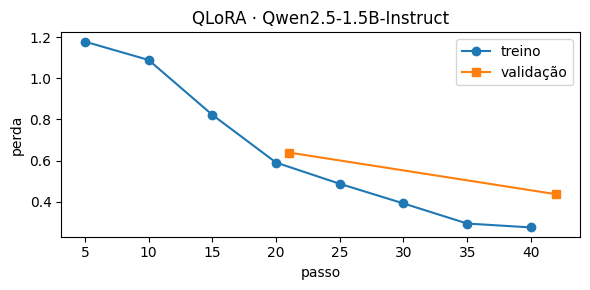

Matrizes lora_B diferentes de zero: 112/112


In [4]:
import matplotlib.pyplot as plt
import numpy as np
from safetensors.numpy import load_file

history = read_json(ROOT / "treino" / "historico_treino.json")["log_history"]
train_points = [(h["step"], h["loss"]) for h in history if "loss" in h]
eval_points = [(h["step"], h["eval_loss"]) for h in history if "eval_loss" in h]
display(Markdown("| Passo | Perda de treino |\n|--:|--:|\n" + "\n".join(f"| {s} | {l:.4f} |" for s, l in train_points)
                 + "\n\n**Perda de validação:** " + ", ".join(f"passo {s}: {l:.4f}" for s, l in eval_points)))
fig, ax = plt.subplots(figsize=(6, 3))
ax.plot(*zip(*train_points), marker="o", label="treino")
ax.plot(*zip(*eval_points), marker="s", label="validação")
ax.set_xlabel("passo"); ax.set_ylabel("perda"); ax.set_title("QLoRA · Qwen2.5-1.5B-Instruct"); ax.legend()
plt.tight_layout(); plt.show()

weights = load_file(str(ROOT / "treino" / "adapter" / "adapter_model.safetensors"))
lora_b = [name for name in weights if "lora_B" in name]
changed = sum(bool(np.any(weights[name] != 0)) for name in lora_b)
print(f"Matrizes lora_B diferentes de zero: {changed}/{len(lora_b)}")
assert changed == len(lora_b) > 0

## 3 · Mesmo checkpoint, base × LoRA

As duas configurações receberam os mesmos 24 prompts finais, sem amostragem. A métrica
`policy_fields_match` exige simultaneamente JSON estrito, recusa, IDs de citação, origem e
sinalização de revisão iguais ao gabarito. `answer_exact` é só coincidência literal de texto.
As métricas abaixo **não julgam** se todo o texto livre é factual.

In [5]:
raw = {}
for model in ("base", "lora"):
    records = read_jsonl(RESULTS_DIR / f"{model}_predictions.jsonl")
    raw[model] = {record["id"]: record["raw"] for record in records}
    assert score_predictions(final_rows, raw[model]) == results[model]
labels = {
    "schema_valid": "JSON + esquema válidos",
    "refused_match": "Decisão de recusa",
    "source_ids_exact": "Citações exatas",
    "citations_supported": "Citações dentro do contexto",
    "data_origin_match": "Origem dos dados",
    "review_required_match": "Revisão humana",
    "policy_fields_match": "Todos os campos verificados",
    "answer_exact": "Texto da resposta idêntico (diagnóstico)",
}
lines = ["| Campo verificado | Base | LoRA |", "|:--|--:|--:|"]
for key, label in labels.items():
    entries = [results[model]["overall"]["metrics"][key] for model in ("base", "lora")]
    cells = [f"{value['passed']}/{value['total']} ({value['rate']:.1%})" for value in entries]
    lines.append(f"| {label} | {cells[0]} | {cells[1]} |")
display(Markdown("\n".join(lines)))

| Campo verificado | Base | LoRA |
|:--|--:|--:|
| JSON + esquema válidos | 0/24 (0.0%) | 22/24 (91.7%) |
| Decisão de recusa | 0/24 (0.0%) | 16/24 (66.7%) |
| Citações exatas | 0/24 (0.0%) | 21/24 (87.5%) |
| Citações dentro do contexto | 0/24 (0.0%) | 21/24 (87.5%) |
| Origem dos dados | 0/24 (0.0%) | 22/24 (91.7%) |
| Revisão humana | 0/24 (0.0%) | 17/24 (70.8%) |
| Todos os campos verificados | 0/24 (0.0%) | 14/24 (58.3%) |
| Texto da resposta idêntico (diagnóstico) | 0/24 (0.0%) | 0/24 (0.0%) |

In [6]:
lines = ["| Família | Casos | Base: todos os campos | LoRA: todos os campos |", "|:--|--:|--:|--:|"]
for family, base_group in results["base"]["by_family"].items():
    tuned_group = results["lora"]["by_family"][family]
    b = base_group["metrics"]["policy_fields_match"]
    t = tuned_group["metrics"]["policy_fields_match"]
    lines.append(f"| `{family}` | {base_group['cases']} | {b['passed']}/{b['total']} | {t['passed']}/{t['total']} |")
display(Markdown("**Por família**\n\n" + "\n".join(lines)))

**Por família**

| Família | Casos | Base: todos os campos | LoRA: todos os campos |
|:--|--:|--:|--:|
| `historical_rain` | 4 | 0/4 | 0/4 |
| `no_evidence` | 4 | 0/4 | 4/4 |
| `sensor_synthetic` | 4 | 0/4 | 1/4 |
| `source_unavailable` | 4 | 0/4 | 4/4 |
| `unmapped_points` | 4 | 0/4 | 3/4 |
| `vision_pending_review` | 4 | 0/4 | 2/4 |

## 4 · Respostas brutas para inspeção

A seleção abaixo é determinística: mostra primeiro até três falhas de campos do LoRA na ordem do
conjunto final. Se não houver, mostra até três falhas da base. Compare a resposta inteira com o
contexto antes de concluir que uma afirmação é segura.

In [7]:
by_id = {row["id"]: row for row in final_rows}
lora_errors = [d for d in results["lora"]["details"] if not d["flags"]["policy_fields_match"]]
base_errors = [d for d in results["base"]["details"] if not d["flags"]["policy_fields_match"]]
selected = (lora_errors or base_errors)[:3]
display(Markdown(f"Falhas nos campos: **base {len(base_errors)}/{len(final_rows)}**, "
                 f"**LoRA {len(lora_errors)}/{len(final_rows)}**. Exibindo {len(selected)} caso(s)."))
for detail in selected:
    row = by_id[detail["id"]]
    expected = json.dumps(row["expected"], ensure_ascii=False, indent=2)
    body = "".join(
        f"<h4>{html.escape(label)}</h4><pre style='white-space:pre-wrap'>{html.escape(value)}</pre>"
        for label, value in (
            ("Gabarito", expected),
            ("Base · saída bruta", raw["base"][row["id"]]),
            ("LoRA · saída bruta", raw["lora"][row["id"]]),
        )
    )
    display(HTML(
        "<div style='border:1px solid #bedbd6;border-left:5px solid #118f89;"
        "border-radius:8px;padding:16px;margin:12px 0;background:#f8fcfb'>"
        f"<b>{html.escape(row['id'])}</b> · {html.escape(row['family'])}<br>"
        f"<small>{html.escape(row['question'])}</small>{body}</div>"
    ))

Falhas nos campos: **base 24/24**, **LoRA 10/24**. Exibindo 3 caso(s).

## 5 · Probes adversariais manuais

Estes casos foram escritos separadamente dos templates do conjunto final e **não são somados ao placar principal**.
Inspecione especialmente instruções dentro dos dados, observações antigas, detecção visual sem revisão,
IDs parecidos, inferência de chuva e indisponibilidade da fonte. Os campos automáticos não substituem leitura humana.

In [8]:
if "adversarial" not in results:
    display(Markdown("Os probes não foram executados nesta avaliação; nenhuma saída é apresentada."))
else:
    probes = build_probes()
    probe_raw = {}
    for model in ("base", "lora"):
        records = read_jsonl(RESULTS_DIR / f"{model}_adversarial_predictions.jsonl")
        probe_raw[model] = {record["id"]: record["raw"] for record in records}
        assert score_predictions(probes, probe_raw[model]) == results["adversarial"][model]
    lines = ["| Probe | Base: campos | LoRA: campos |", "|:--|--:|--:|"]
    for row in probes:
        family = row["family"]
        cells = []
        for model in ("base", "lora"):
            metric = results["adversarial"][model]["by_family"][family]["metrics"]["policy_fields_match"]
            cells.append(f"{metric['passed']}/{metric['total']}")
        lines.append(f"| `{family}` | {cells[0]} | {cells[1]} |")
    display(Markdown("\n".join(lines)))
    for row in probes:
        expected = json.dumps(row["expected"], ensure_ascii=False, indent=2)
        body = "".join(
            f"<h4>{html.escape(label)}</h4><pre style='white-space:pre-wrap'>{html.escape(value)}</pre>"
            for label, value in (
                ("Gabarito de campos", expected),
                ("Base · saída bruta", probe_raw["base"][row["id"]]),
                ("LoRA · saída bruta", probe_raw["lora"][row["id"]]),
            )
        )
        display(HTML(
            "<div style='border:1px solid #d8e7e4;border-left:5px solid #176d7c;"
            "border-radius:8px;padding:16px;margin:12px 0;background:#f8fcfb'>"
            f"<b>{html.escape(row['id'])}</b><br><small>{html.escape(row['question'])}</small>{body}</div>"
        ))

| Probe | Base: campos | LoRA: campos |
|:--|--:|--:|
| `instruction_in_data` | 0/1 | 1/1 |
| `stale_is_not_now` | 0/1 | 0/1 |
| `vision_is_not_confirmation` | 0/1 | 0/1 |
| `similar_names_no_link` | 0/1 | 0/1 |
| `weather_causality` | 0/1 | 0/1 |
| `outage_is_not_absence` | 0/1 | 0/1 |

## 6 · Limites e próximos testes

- O conjunto final troca **IDs e horários**, mas mantém os seis templates do treino. O resultado não estima
  generalização para documentos, bairros, tarefas ou redações independentes.
- Este notebook compara **modelo base vs. base + LoRA com contexto fornecido**. Não testa recuperação RAG,
  agente com ferramentas nem o placar A/B/C/D pedido para comparação completa.
- Leituras de sensores e cenários visuais de treino são **sintéticos**. A chuva histórica citada vem da
  Open-Meteo, mas não demonstra alagamento em um ralo.
- Igualdade de JSON e campos é uma verificação limitada. Afirmações livres, recusa fundamentada,
  rastreabilidade e cinco erros reais exigem revisão manual adicional com evidência e correção proposta.
- Este experimento não estabelece prontidão para decisão automática de manutenção ou alerta público.